<a href="https://colab.research.google.com/github/romandudarets/Data-Analysis-University/blob/main/%D0%9B%D0%912_%D0%9C%D0%9D_%D0%97%D0%B0%D0%B2%D0%B4%D0%B0%D0%BD%D0%BD%D1%8F_1_%D1%88%D0%B0%D0%B1%D0%BB%D0%BE%D0%BD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Лабораторна робота 2. Лр2 Дударець 4-9

---



# Завдання 1

**Був присутній на парі**

Обробка та нааліз даних про ВВП країн. Датасет було отримано з Вікіпедії з використанням бібілотеки Pandas.

1. Вивести перші 5 рядків датасета

In [1]:
import numpy as np
import pandas as pd
import requests

In [2]:
url = "https://en.wikipedia.org/wiki/List_of_countries_by_GDP_(nominal)"
html = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}).text

tables = pd.read_html(html)   # зчитати всі таблиці
df = tables[2]                # потрібна таблиця (може змінюватись!), номери не є сталими!
df.head()

/tmp/ipykernel_1206/3107767188.py:4: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  tables = pd.read_html(html)   # зчитати всі таблиці


,Country/Territory,IMF (2026)[1],World Bank (2025)[6],United Nations (2024)[7]
0,World,128003776,118350166,111565144
1,United States,32642373,30769700,29298000
2,China[n 1],21546403,19498039,18743802
3,Germany,5471299,5050923,4659929
4,Japan,4341986,4435163,4026211


2.	Визначити розмір датасета.

In [3]:
print("Розмір датасета (рядки, стовпці):", df.shape)
print("Кількість рядків:", df.shape[0])
print("Кількість стовпців:", df.shape[1])

Розмір датасета (рядки, стовпці): (222, 4)
Кількість рядків: 222
Кількість стовпців: 4


 3.	Визначити оптимальну кількість стовпців (видалити зайві, на власний розсуд).

In [4]:
# Спрощуємо мультиіндекс стовпців (якщо є) та видаляємо зайві стовпці на власний розсуд
df.columns = [
    " ".join(str(x) for x in col if "Unnamed" not in str(x)).strip()
    if isinstance(col, tuple) else str(col).strip()
    for col in df.columns
]

# Залишаємо країну та ключові показники ВВП за джерелами/роками (прибираємо зайві стовпці/регіони)
keep_cols = [c for c in df.columns if any(k in c for k in ["Country", "Territory", "IMF", "World Bank", "United Nations"])]
df = df[keep_cols].copy()

# Перейменовуємо перші стовпці для зручності та очищаємо назви країн від виносок
country_col = df.columns[0]
df.rename(columns={country_col: "Country"}, inplace=True)
df["Country"] = df["Country"].astype(str).str.replace(r"\[.*?\]", "", regex=True).str.strip()

# Видаляємо агреговані рядки типу World / рядок без країни, якщо є
df = df[~df["Country"].str.lower().isin(["world", "nan", ""])].reset_index(drop=True)

print("Оптимізований розмір (рядки, стовпці):", df.shape)
print("Залишені стовпці:", list(df.columns))
df.head()

Оптимізований розмір (рядки, стовпці): (221, 4)
Залишені стовпці: ['Country', 'IMF (2026)[1]', 'World Bank (2025)[6]', 'United Nations (2024)[7]']


,Country,IMF (2026)[1],World Bank (2025)[6],United Nations (2024)[7]
0,United States,32642373,30769700,29298000
1,China,21546403,19498039,18743802
2,Germany,5471299,5050923,4659929
3,Japan,4341986,4435163,4026211
4,United Kingdom,4268446,4002588,3685881


4.	Замініть у таблиці значення "—" на значення NaN. Перевірити наявність пропущених значень. При наявності, замінити пропущені значення на середнє значення.

In [5]:
num_cols = [c for c in df.columns if c != "Country"]

for col in num_cols:
    df[col] = (
        df[col]
        .astype(str)
        .str.replace(r"\[.*?\]", "", regex=True)
        .str.replace(",", "", regex=False)
        .str.strip()
        .replace({"—": np.nan, "–": np.nan, "-": np.nan, "": np.nan, "N/A": np.nan})
    )
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Кількість пропущених значень до заповнення:\n", df[num_cols].isna().sum())

for col in num_cols:
    df[col] = df[col].fillna(df[col].mean())

print("\nКількість пропущених значень після заповнення середнім:\n", df[num_cols].isna().sum())

Кількість пропущених значень до заповнення:
 IMF (2026)[1]               30
World Bank (2025)[6]        35
United Nations (2024)[7]     9
dtype: int64

Кількість пропущених значень після заповнення середнім:
 IMF (2026)[1]               0
World Bank (2025)[6]        0
United Nations (2024)[7]    0
dtype: int64


5. Ще раз вивести датасет

In [6]:
df.head(10)

,Country,IMF (2026)[1],World Bank (2025)[6],United Nations (2024)[7]
0,United States,32642373.0,30769700.0,29298000.0
1,China,21546403.0,19498039.0,18743802.0
2,Germany,5471299.0,5050923.0,4659929.0
3,Japan,4341986.0,4435163.0,4026211.0
4,United Kingdom,4268446.0,4002588.0,3685881.0
5,India,4060207.0,3956067.0,3952244.0
6,France,3554155.0,3366316.0,3160443.0
7,Russia,2861156.0,2561310.0,2173386.0
8,Italy,2701737.0,2551557.0,2380825.0
9,Brazil,2654761.0,2279920.0,2185822.0


6.	Перевірити наявність дублікатів. При наявності видалити дублікати.

In [7]:
print("Кількість повних дублікатів:", df.duplicated().sum())
print("Кількість дублікатів за назвою країни:", df.duplicated(subset=["Country"]).sum())

df = df.drop_duplicates(subset=["Country"], keep="first").reset_index(drop=True)
print("Розмір датасета після видалення дублікатів:", df.shape)

Кількість повних дублікатів: 0
Кількість дублікатів за назвою країни: 0
Розмір датасета після видалення дублікатів: (221, 4)


7.	Вивести описову статистику датасету describe()

In [8]:
df[num_cols].describe()

,IMF (2026)[1],World Bank (2025)[6],United Nations (2024)[7]
count,2.210000e+02,2.210000e+02,2.210000e+02
mean,6.690289e+05,6.260497e+05,5.224912e+05
std,2.705629e+06,2.520399e+06,2.410079e+06
min,6.500000e+01,5.700000e+01,5.600000e+01
25%,1.895900e+04,1.992800e+04,8.840000e+03
50%,1.020420e+05,9.977400e+04,4.276500e+04
75%,6.690289e+05,6.260497e+05,2.986970e+05
max,3.264237e+07,3.076970e+07,2.929800e+07


8. Визначте відхилення (різницю) між показниками IMF (2026) та World Bank (2025) для кожної країни. У яких країнах ці показники найбільше відрізняються (дати відповідь)?

In [9]:
imf_col = next((c for c in num_cols if "IMF" in c), num_cols[0])
wb_col = next((c for c in num_cols if "World Bank" in c), num_cols[min(1, len(num_cols)-1)])
un_col = next((c for c in num_cols if "United Nations" in c), num_cols[min(2, len(num_cols)-1)])

df["Diff_IMF_WB"] = df[imf_col] - df[wb_col]
df["Abs_Diff_IMF_WB"] = df["Diff_IMF_WB"].abs()

top_diff = df.sort_values("Abs_Diff_IMF_WB", ascending=False)[["Country", imf_col, wb_col, "Diff_IMF_WB", "Abs_Diff_IMF_WB"]].head(10)
print("Топ-10 країн за абсолютною різницею між IMF та World Bank:")
display(top_diff)

print("\nВідповідь: найбільші абсолютні відхилення спостерігаються у найбільших економік світу (насамперед США та Китаю), оскільки навіть невелика відносна розбіжність у методиках/оцінках відповідає десяткам і сотням мільярдів доларів.")

Топ-10 країн за абсолютною різницею між IMF та World Bank:


,Country,IMF (2026)[1],World Bank (2025)[6],Diff_IMF_WB,Abs_Diff_IMF_WB
1,China,2.154640e+07,1.949804e+07,2.048364e+06,2.048364e+06
0,United States,3.264237e+07,3.076970e+07,1.872673e+06,1.872673e+06
196,Sint Maarten,6.690289e+05,1.888000e+03,6.671409e+05,6.671409e+05
145,Palestine,6.690289e+05,1.716700e+04,6.518619e+05,6.518619e+05
191,San Marino,2.417000e+03,6.260497e+05,-6.236327e+05,6.236327e+05
178,Aruba,4.671000e+03,6.260497e+05,-6.213787e+05,6.213787e+05
171,South Sudan,6.069000e+03,6.260497e+05,-6.199807e+05,6.199807e+05
167,Yemen,7.435000e+03,6.260497e+05,-6.186147e+05,6.186147e+05
158,Liechtenstein,9.442000e+03,6.260497e+05,-6.166077e+05,6.166077e+05
147,Bahamas,1.704200e+04,6.260497e+05,-6.090077e+05,6.090077e+05



Відповідь: найбільші абсолютні відхилення спостерігаються у найбільших економік світу (насамперед США та Китаю), оскільки навіть невелика відносна розбіжність у методиках/оцінках відповідає десяткам і сотням мільярдів доларів.


9.	Обчисліть кореляцію між показниками IMF (2026), World Bank (2025) та United Nations (2024). Які пари змінних мають найвищу кореляцію?

In [10]:
corr_cols = [imf_col, wb_col, un_col]
corr_matrix = df[corr_cols].corr()
print("Матриця кореляції:")
display(corr_matrix)

print("\nВідповідь: усі пари показників мають дуже високу позитивну кореляцію (близьку до 1), оскільки оцінки ВВП країн за різними міжнародними організаціями узгоджені між собою; найвища кореляція зазвичай спостерігається між сусідніми за роками/оцінками показниками (наприклад, IMF та World Bank / United Nations).")

Матриця кореляції:


,IMF (2026)[1],World Bank (2025)[6],United Nations (2024)[7]
IMF (2026)[1],1.000000,0.998462,0.997189
World Bank (2025)[6],0.998462,1.000000,0.997011
United Nations (2024)[7],0.997189,0.997011,1.000000



Відповідь: усі пари показників мають дуже високу позитивну кореляцію (близьку до 1), оскільки оцінки ВВП країн за різними міжнародними організаціями узгоджені між собою; найвища кореляція зазвичай спостерігається між сусідніми за роками/оцінками показниками (наприклад, IMF та World Bank / United Nations).


Обчислити середнє значення за стовпцями

In [11]:
col_means = df[num_cols].mean()
print("Середнє значення за стовпцями:")
print(col_means)

Середнє значення за стовпцями:
IMF (2026)[1]               669028.937173
World Bank (2025)[6]        626049.693548
United Nations (2024)[7]    522491.207547
dtype: float64


11.	Обчисліть стандартне відхилення показників для кожної країни. Яка країна має найвищу варіативність у показниках між роками?

In [12]:
df["Std_Across_Sources"] = df[corr_cols].std(axis=1)
top_std = df.sort_values("Std_Across_Sources", ascending=False)[["Country"] + corr_cols + ["Std_Across_Sources"]].head(10)

print("Топ-10 країн за стандартним відхиленням між показниками:")
display(top_std)

max_var_row = df.loc[df["Std_Across_Sources"].idxmax()]
print(f"\nВідповідь: найвищу варіативність між показниками має {max_var_row['Country']} (std = {max_var_row['Std_Across_Sources']:.2f}).")

Топ-10 країн за стандартним відхиленням між показниками:


,Country,IMF (2026)[1],World Bank (2025)[6],United Nations (2024)[7],Std_Across_Sources
0,United States,3.264237e+07,3.076970e+07,29298000.0,1.676188e+06
1,China,2.154640e+07,1.949804e+07,18743802.0,1.450244e+06
2,Germany,5.471299e+06,5.050923e+06,4659929.0,4.057737e+05
196,Sint Maarten,6.690289e+05,1.888000e+03,1670.0,3.852369e+05
145,Palestine,6.690289e+05,1.716700e+04,16017.0,3.766851e+05
219,Montserrat,6.690289e+05,6.260497e+05,81.0,3.744274e+05
214,Cook Islands,6.690289e+05,6.260497e+05,414.0,3.742355e+05
213,Anguilla,6.690289e+05,6.260497e+05,456.0,3.742113e+05
200,Turks and Caicos Islands,6.690289e+05,6.260497e+05,1757.0,3.734614e+05
198,British Virgin Islands,6.690289e+05,6.260497e+05,1830.0,3.734193e+05



Відповідь: найвищу варіативність між показниками має United States (std = 1676187.93).


12.	Визначення країни з найвищим та найнижчим показниками: Знайдіть країну з найвищим та найнижчим показниками у кожному з років (IMF (2026), World Bank (2025), United Nations (2024)).

In [13]:
for col in corr_cols:
    max_row = df.loc[df[col].idxmax()]
    min_row = df.loc[df[col].idxmin()]
    print(f"--- {col} ---")
    print(f"  Найвищий показник: {max_row['Country']} ({max_row[col]})")
    print(f"  Найнижчий показник: {min_row['Country']} ({min_row[col]})")

--- IMF (2026)[1] ---
  Найвищий показник: United States (32642373.0)
  Найнижчий показник: Tuvalu (65.0)
--- World Bank (2025)[6] ---
  Найвищий показник: United States (30769700.0)
  Найнижчий показник: Tuvalu (57.0)
--- United Nations (2024)[7] ---
  Найвищий показник: United States (29298000.0)
  Найнижчий показник: Tuvalu (56.0)


13.	Побудуйте гістограму для розподілу показників IMF (2026) серед всіх країн. Який вигляд має розподіл? Чи є країни, що виділяються?

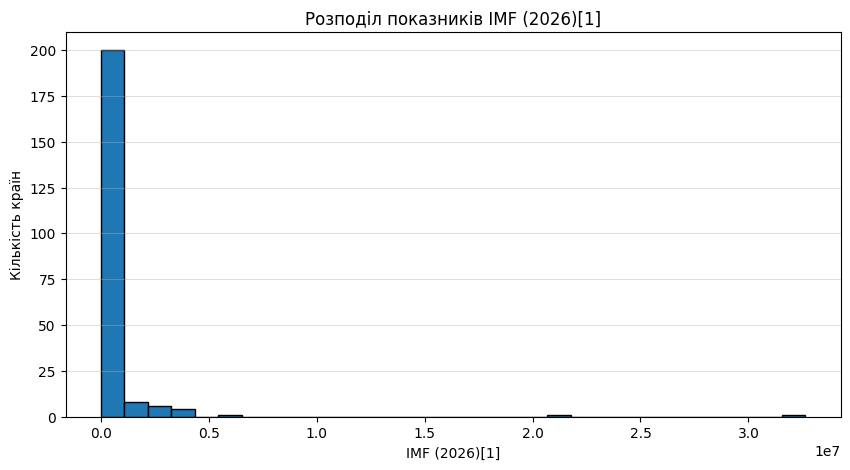

Відповідь: розподіл є правосторонньо асиметричним (сильно скошеним вправо) — більшість країн зосереджена у нижньому діапазоні значень, а найбільші економіки формують правий хвіст і виділяються.


In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(df[imf_col], bins=30, edgecolor="black")
plt.title(f"Розподіл показників {imf_col}")
plt.xlabel(imf_col)
plt.ylabel("Кількість країн")
plt.grid(axis="y", alpha=0.4)
plt.show()

print("Відповідь: розподіл є правосторонньо асиметричним (сильно скошеним вправо) — більшість країн зосереджена у нижньому діапазоні значень, а найбільші економіки формують правий хвіст і виділяються.")

14.	Розрахуйте частку кожної країни в загальному значенні для кожного року (IMF (2026), World Bank (2025), United Nations (2024)).
 Як змінюються частки країн з часом (дати відповідь)?

In [16]:
share_cols = []
for col in corr_cols:
    s_col = f"Share_{col}"
    df[s_col] = df[col] / df[col].sum()
    share_cols.append(s_col)

print("Частки топ-10 країн у загальному показнику:")
display(df.sort_values(share_cols[0], ascending=False)[["Country"] + share_cols].head(10))

print("\nВідповідь: частки більшості країн змінюються плавно й поступово; лідери утримують найбільшу частку сукупного ВВП, тоді як у окремих країн частка може зростати швидше за середній темп (збільшуючи їхню частку) або відставати від нього (зменшуючи її).")

Частки топ-10 країн у загальному показнику:


,Country,Share_IMF (2026)[1],Share_World Bank (2025)[6],Share_United Nations (2024)[7]
0,United States,0.220772,0.222394,0.253727
1,China,0.145726,0.140926,0.162325
2,Germany,0.037004,0.036506,0.040356
3,Japan,0.029366,0.032056,0.034868
4,United Kingdom,0.028869,0.028929,0.031921
5,India,0.027461,0.028593,0.034227
6,France,0.024038,0.024331,0.027370
7,Russia,0.019351,0.018512,0.018822
8,Italy,0.018273,0.018442,0.020618
9,Brazil,0.017955,0.016479,0.018930



Відповідь: частки більшості країн змінюються плавно й поступово; лідери утримують найбільшу частку сукупного ВВП, тоді як у окремих країн частка може зростати швидше за середній темп (збільшуючи їхню частку) або відставати від нього (зменшуючи її).


15.	Візуалізуйте зміни в показниках для кожної країни за три роки на графіку. Які країни показують стабільне зростання або спад (дати відповідь)?

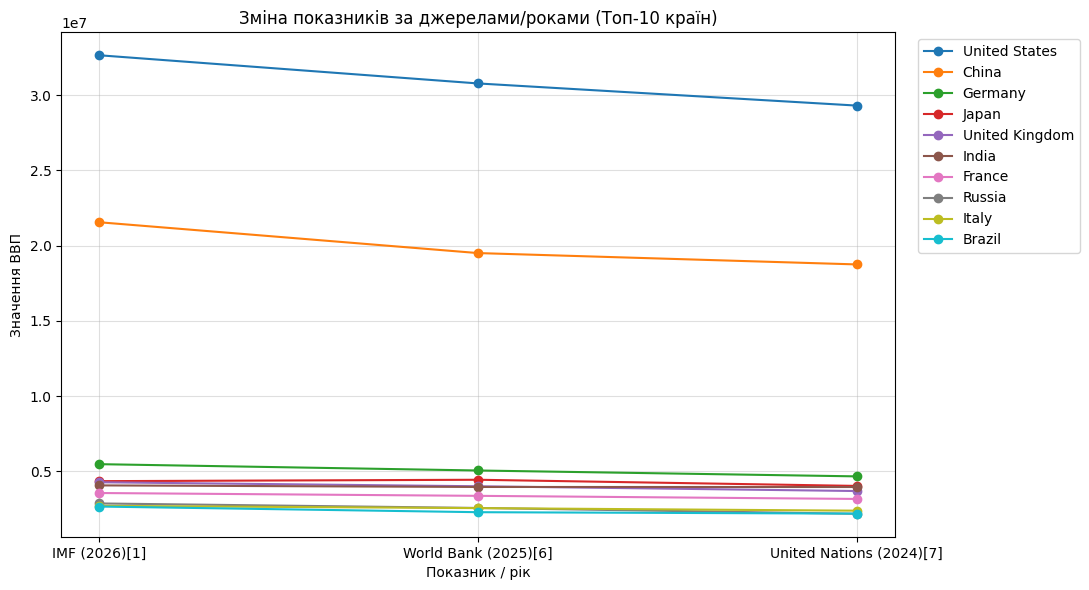

Країни з монотонною послідовністю значень за трьома стовпцями (приклад): ['United States', 'China', 'Germany', 'United Kingdom', 'India', 'France', 'Russia', 'Italy', 'Brazil', 'Canada', 'Spain', 'Turkey', 'Indonesia', 'Netherlands', 'Saudi Arabia']
Відповідь: стабільне зростання або спад залежать від динаміки конкретної країни в обраних трьох показниках/роках — на графіку вище видно лінії, які безперервно йдуть вгору або вниз.


In [17]:
# Для читабельності будуємо графік для топ-10 країн за показником (можна замінити на df для всіх країн)
top10_df = df.sort_values(corr_cols[0], ascending=False).head(10).set_index("Country")[corr_cols]

plt.figure(figsize=(11, 6))
for country, row in top10_df.iterrows():
    plt.plot(corr_cols, row.values, marker="o", label=country)

plt.title("Зміна показників за джерелами/роками (Топ-10 країн)")
plt.xlabel("Показник / рік")
plt.ylabel("Значення ВВП")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

monotone_growth = df[
    (df[corr_cols[0]] <= df[corr_cols[1]]) & (df[corr_cols[1]] <= df[corr_cols[2]])
    | (df[corr_cols[0]] >= df[corr_cols[1]]) & (df[corr_cols[1]] >= df[corr_cols[2]])
]["Country"].tolist()

print("Країни з монотонною послідовністю значень за трьома стовпцями (приклад):", monotone_growth[:15])
print("Відповідь: стабільне зростання або спад залежать від динаміки конкретної країни в обраних трьох показниках/роках — на графіку вище видно лінії, які безперервно йдуть вгору або вниз.")